In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [16]:
excel_file = pd.ExcelFile('/content/AdPulse_BI_Dataset_Messy_Practice.xlsx')
print(excel_file.sheet_names)

['Channels', 'Campaigns', 'Ad_Groups', 'Daily_Performance', 'Conversions', 'Touchpoints']


In [17]:
for sheet_name, data in all_sheets.items():
    print("Sheet Name:", sheet_name)
    display(data.head())

Sheet Name: Channels


,Channel_ID,Channel_Name,Channel_Type,Platform,Channel_Group,Imported_By,Temp_Column
0,1,google ads,Paid Search,Google,Search,system_import,1
1,2,FACEBOOK ADS,Paid Social,Meta,Social,system_import,2
2,3,Instagram Ads,Paid Social,tik tok,Social,system_import,3
3,4,TikTok Ads,Paid Social,TikTok,Social,system_import,4
4,5,YouTube Ads,Paid Video,Google,Video,system_import,5


Sheet Name: Campaigns


,Campaign_ID,Campaign_Name,Channel_ID,Objective,Target_Country,Target_Audience,Start_Date,End_Date,Planned_Budget,Campaign_Status,Internal_Comment,Legacy_Code
0,1001,Google_Awareness_01,1,Awareness,Egypt,18-24,22/01/2025,17/06/2025,29138.31,completed,temporary field - not for analysis,OLD-0
1,1002,Google_Traffic_02,1,Traffic,KSA,25-34,01-21-2025,04-Jun-2025,10179.75,paused,temporary field - not for analysis,OLD-1
2,1003,Google_Conversion_03,1,Conversion,UAE,35-44,26/06/2025,2025-11-17,48233.54,Active,temporary field - not for analysis,OLD-2
3,1004,Google_Retargeting_04,1,Retargeting,Jordan,All Adults,NaN,26-Oct-2025,25393.89,Paused,temporary field - not for analysis,OLD-3
4,1005,Google_Awareness_05,1,Awareness,Egypt,18-24,2025/07/07,2025-11-10,50251.89,Active,temporary field - not for analysis,OLD-4


Sheet Name: Ad_Groups


,AdGroup_ID,Campaign_ID,AdGroup_Name,Audience_Type,Device_Targeting
0,5001,1001,AG_1001_1,Prospecting,Mobile
1,5002,1001,AG_1001_2,Retargeting,Desktop
2,5003,1002,AG_1002_1,Prospecting,Mobile
3,5004,1002,AG_1002_2,Retargeting,Desktop
4,5005,1003,AG_1003_1,Prospecting,Mobile


... (2 outputs left out)

Sheet Name: Conversions


,Conversion_ID,Customer_ID,Conversion_Date,Revenue,First_Touch_Channel_ID,Last_Touch_Channel_ID,Touch_Count,Order_ID,Country,Conversion_Device,Export_Note
0,1,113643,2025-11-22,3037.67,6,1,2,ORD-000001,UAE,Web,generated export
1,2,141312,2025-08-29,1642.97,8,1,2,ORD-000002,Jordan,Mobile App,generated export
2,3,124505,2025-07-12,1997.29,1,2,3,ORD-000003,KSA,Web,generated export
3,4,143464,2025-08-06,1859.61,5,3,2,ORD-000004,Jordan,Mobile App,generated export
4,5,141957,2025-11-07,291.66,8,3,3,ORD-000005,Jordan,Web,generated export


Sheet Name: Touchpoints


,Touchpoint_ID,Conversion_ID,Customer_ID,Touch_Date,Channel_ID,Touch_Sequence,Touchpoint_Type,Raw_Source_File
0,1,1,113643,2025-11-12,6,1,Click,touchpoints_backup.csv
1,2,1,113643,2025-11-17,1,2,Conversion,touchpoints_backup.csv
2,3,2,141312,2025-08-05,8,1,Impression,touchpoints_backup.csv
3,4,2,141312,2025-08-18,1,2,Conversion,touchpoints_backup.csv
4,5,3,124505,2025-06-21,1,1,Site Visit,touchpoints_backup.csv


In [19]:
channels = all_sheets["Channels"]
campaigns = all_sheets["Campaigns"]
ad_groups = all_sheets["Ad_Groups"]
daily_performance = all_sheets["Daily_Performance"]
conversions = all_sheets["Conversions"]
touchpoints = all_sheets["Touchpoints"]

dataframes = {
    "Channels": channels,
    "Campaigns": campaigns,
    "Ad_Groups": ad_groups,
    "Daily_Performance": daily_performance,
    "Conversions": conversions,
    "Touchpoints": touchpoints
}

print("All 6 tables are ready.")

All 6 tables are ready.


In [22]:
for name, df in dataframes.items():
    print(f"\n{name}")
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])


Channels
Rows: 9
Columns: 7

Campaigns
Rows: 90
Columns: 12

Ad_Groups
Rows: 180
Columns: 5

Daily_Performance
Rows: 260120
Columns: 11

Conversions
Rows: 12000
Columns: 11

Touchpoints
Rows: 41976
Columns: 8


In [23]:
for name, df in dataframes.items():
    print(f"\n{name}")
    print(df.columns.tolist())


Channels
['Channel_ID', 'Channel_Name', 'Channel_Type', 'Platform', 'Channel_Group', 'Imported_By', 'Temp_Column']

Campaigns
['Campaign_ID', 'Campaign_Name', 'Channel_ID', 'Objective', 'Target_Country', 'Target_Audience', 'Start_Date', 'End_Date', 'Planned_Budget', 'Campaign_Status', 'Internal_Comment', 'Legacy_Code']

Ad_Groups
['AdGroup_ID', 'Campaign_ID', 'AdGroup_Name', 'Audience_Type', 'Device_Targeting']

Daily_Performance
['Date', 'Campaign_ID', 'AdGroup_ID', 'Channel_ID', 'Spend', 'Impressions', 'Clicks', 'Conversions', 'Conversion_Value', 'Upload_Batch', 'Unused_Flag']

Conversions
['Conversion_ID', 'Customer_ID', 'Conversion_Date', 'Revenue', 'First_Touch_Channel_ID', 'Last_Touch_Channel_ID', 'Touch_Count', 'Order_ID', 'Country', 'Conversion_Device', 'Export_Note']

Touchpoints
['Touchpoint_ID', 'Conversion_ID', 'Customer_ID', 'Touch_Date', 'Channel_ID', 'Touch_Sequence', 'Touchpoint_Type', 'Raw_Source_File']


In [24]:
for name, df in dataframes.items():
    print(f"\n{'='*50}")
    print(name)
    print("="*50)
    df.info()


Channels
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Channel_ID     9 non-null      int64 
 1   Channel_Name   9 non-null      object
 2   Channel_Type   9 non-null      object
 3   Platform       9 non-null      object
 4   Channel_Group  9 non-null      object
 5   Imported_By    9 non-null      object
 6   Temp_Column    9 non-null      int64 
dtypes: int64(2), object(5)
memory usage: 636.0+ bytes

Campaigns
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Campaign_ID       90 non-null     int64  
 1   Campaign_Name     90 non-null     object 
 2   Channel_ID        90 non-null     int64  
 3   Objective         90 non-null     object 
 4   Target_Country    90 non-null     object 
 5   

In [25]:
for name, df in dataframes.items():
    print(f"\n{'='*50}")
    print(name)
    print("="*50)
    display(df.describe(include="all").T)


Channels


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Channel_ID,9.0,NaN,NaN,NaN,5.0,2.738613,1.0,3.0,5.0,7.0,9.0
Channel_Name,9,9,google ads,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Channel_Type,9,7,Paid Social,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Platform,9,6,Google,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Channel_Group,9,6,Social,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Imported_By,9,1,system_import,9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Temp_Column,9.0,NaN,NaN,NaN,5.0,2.738613,1.0,3.0,5.0,7.0,9.0



Campaigns


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Campaign_ID,90.0,NaN,NaN,NaN,1045.5,26.124701,1001.0,1023.25,1045.5,1067.75,1090.0
Campaign_Name,90,90,Google_Awareness_01,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Channel_ID,90.0,NaN,NaN,NaN,4.6,2.642777,1.0,2.0,4.0,7.0,9.0
Objective,90,8,Awareness,21,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Target_Country,90,4,Egypt,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Target_Audience,90,4,18-24,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Start_Date,82,77,31/02/2025,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
End_Date,84,79,2025-09-14,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Planned_Budget,90.0,NaN,NaN,NaN,31432.313556,17146.142254,5981.02,14713.24,29139.22,48269.015,58388.39
Campaign_Status,90,6,Active,45,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Ad_Groups


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
AdGroup_ID,180.0,NaN,NaN,NaN,5090.5,52.105662,5001.0,5045.75,5090.5,5135.25,5180.0
Campaign_ID,180.0,NaN,NaN,NaN,1045.5,26.051625,1001.0,1023.0,1045.5,1068.0,1090.0
AdGroup_Name,180,180,AG_1001_1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Audience_Type,180,2,Prospecting,90,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Device_Targeting,180,2,Mobile,90,NaN,NaN,NaN,NaN,NaN,NaN,NaN


... (2 outputs left out)


Conversions


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Conversion_ID,12000.0,NaN,NaN,NaN,6000.5,3464.24595,1.0,3000.75,6000.5,9000.25,12000.0
Customer_ID,12000.0,NaN,NaN,NaN,122383.858167,12972.032438,100001.0,111158.25,122073.5,133563.5,144972.0
Conversion_Date,11988,540,2025-12-06,52,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Revenue,11925.0,11535.0,244.49,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
First_Touch_Channel_ID,12000.0,NaN,NaN,NaN,3.91025,2.604757,1.0,2.0,3.0,6.0,9.0
Last_Touch_Channel_ID,12000.0,NaN,NaN,NaN,3.891,2.588341,1.0,2.0,3.0,6.0,9.0
Touch_Count,12000.0,NaN,NaN,NaN,3.494667,1.709693,1.0,2.0,4.0,5.0,6.0
Order_ID,12000,12000,ORD-000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,12000,4,KSA,3025,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Conversion_Device,12000,2,Web,8943,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Touchpoints


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Touchpoint_ID,41976.0,NaN,NaN,NaN,20968.85151,12105.783691,1.0,10484.75,20972.5,31451.25,41936.0
Conversion_ID,41976.0,NaN,NaN,NaN,5978.727559,3470.444889,1.0,2967.75,5976.0,8989.0,12000.0
Customer_ID,41976.0,NaN,NaN,NaN,122498.969983,13043.12628,100001.0,111190.0,122371.0,133795.0,144972.0
Touch_Date,41956,722,2025-01-01,496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Channel_ID,41976.0,NaN,NaN,NaN,3.908996,2.595356,1.0,2.0,3.0,6.0,9.0
Touch_Sequence,41976.0,NaN,NaN,NaN,2.665499,1.490908,1.0,1.0,2.0,4.0,6.0
Touchpoint_Type,41976,5,Conversion,12013,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Raw_Source_File,41976,1,touchpoints_backup.csv,41976,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [26]:
for name, df in dataframes.items():
    print(name)
    print(df.isnull().sum())

Channels
Channel_ID       0
Channel_Name     0
Channel_Type     0
Platform         0
Channel_Group    0
Imported_By      0
Temp_Column      0
dtype: int64
Campaigns
Campaign_ID         0
Campaign_Name       0
Channel_ID          0
Objective           0
Target_Country      0
Target_Audience     0
Start_Date          8
End_Date            6
Planned_Budget      0
Campaign_Status     0
Internal_Comment    0
Legacy_Code         0
dtype: int64
Ad_Groups
AdGroup_ID          0
Campaign_ID         0
AdGroup_Name        0
Audience_Type       0
Device_Targeting    0
dtype: int64
Daily_Performance
Date                 35
Campaign_ID           0
AdGroup_ID            0
Channel_ID            0
Spend               350
Impressions         181
Clicks              220
Conversions         160
Conversion_Value    300
Upload_Batch          0
Unused_Flag           0
dtype: int64
Conversions
Conversion_ID              0
Customer_ID                0
Conversion_Date           12
Revenue                   75
Fi

In [27]:
for name, df in dataframes.items():
    print(name)
    print((df.isnull().sum() / len(df) * 100).round(2))

Channels
Channel_ID       0.0
Channel_Name     0.0
Channel_Type     0.0
Platform         0.0
Channel_Group    0.0
Imported_By      0.0
Temp_Column      0.0
dtype: float64
Campaigns
Campaign_ID         0.00
Campaign_Name       0.00
Channel_ID          0.00
Objective           0.00
Target_Country      0.00
Target_Audience     0.00
Start_Date          8.89
End_Date            6.67
Planned_Budget      0.00
Campaign_Status     0.00
Internal_Comment    0.00
Legacy_Code         0.00
dtype: float64
Ad_Groups
AdGroup_ID          0.0
Campaign_ID         0.0
AdGroup_Name        0.0
Audience_Type       0.0
Device_Targeting    0.0
dtype: float64
Daily_Performance
Date                0.01
Campaign_ID         0.00
AdGroup_ID          0.00
Channel_ID          0.00
Spend               0.13
Impressions         0.07
Clicks              0.08
Conversions         0.06
Conversion_Value    0.12
Upload_Batch        0.00
Unused_Flag         0.00
dtype: float64
Conversions
Conversion_ID             0.00
Customer

In [30]:
for name, df in dataframes.items():
  print(name, df.duplicated().sum())

Channels 0
Campaigns 0
Ad_Groups 0
Daily_Performance 120
Conversions 0
Touchpoints 40


In [31]:
for name, df in dataframes.items():
    print(name)
    display(df.describe())

Channels


,Channel_ID,Temp_Column
count,9.000000,9.000000
mean,5.000000,5.000000
std,2.738613,2.738613
min,1.000000,1.000000
25%,3.000000,3.000000
50%,5.000000,5.000000
75%,7.000000,7.000000
max,9.000000,9.000000


Campaigns


,Campaign_ID,Channel_ID,Planned_Budget
count,90.000000,90.000000,90.000000
mean,1045.500000,4.600000,31432.313556
std,26.124701,2.642777,17146.142254
min,1001.000000,1.000000,5981.020000
25%,1023.250000,2.000000,14713.240000
50%,1045.500000,4.000000,29139.220000
75%,1067.750000,7.000000,48269.015000
max,1090.000000,9.000000,58388.390000


Ad_Groups


,AdGroup_ID,Campaign_ID
count,180.000000,180.000000
mean,5090.500000,1045.500000
std,52.105662,26.051625
min,5001.000000,1001.000000
25%,5045.750000,1023.000000
50%,5090.500000,1045.500000
75%,5135.250000,1068.000000
max,5180.000000,1090.000000


... (2 outputs left out)

Conversions


,Conversion_ID,Customer_ID,First_Touch_Channel_ID,Last_Touch_Channel_ID,Touch_Count
count,12000.00000,12000.000000,12000.000000,12000.000000,12000.000000
mean,6000.50000,122383.858167,3.910250,3.891000,3.494667
std,3464.24595,12972.032438,2.604757,2.588341,1.709693
min,1.00000,100001.000000,1.000000,1.000000,1.000000
25%,3000.75000,111158.250000,2.000000,2.000000,2.000000
50%,6000.50000,122073.500000,3.000000,3.000000,4.000000
75%,9000.25000,133563.500000,6.000000,6.000000,5.000000
max,12000.00000,144972.000000,9.000000,9.000000,6.000000


Touchpoints


,Touchpoint_ID,Conversion_ID,Customer_ID,Channel_ID,Touch_Sequence
count,41976.000000,41976.000000,41976.000000,41976.000000,41976.000000
mean,20968.851510,5978.727559,122498.969983,3.908996,2.665499
std,12105.783691,3470.444889,13043.126280,2.595356,1.490908
min,1.000000,1.000000,100001.000000,1.000000,1.000000
25%,10484.750000,2967.750000,111190.000000,2.000000,1.000000
50%,20972.500000,5976.000000,122371.000000,3.000000,2.000000
75%,31451.250000,8989.000000,133795.000000,6.000000,4.000000
max,41936.000000,12000.000000,144972.000000,9.000000,6.000000


In [34]:
columns = ["Spend", "Impressions", "Clicks", "Conversions","Revenue",
           "Conversion_Value", "Planned_Budget"]

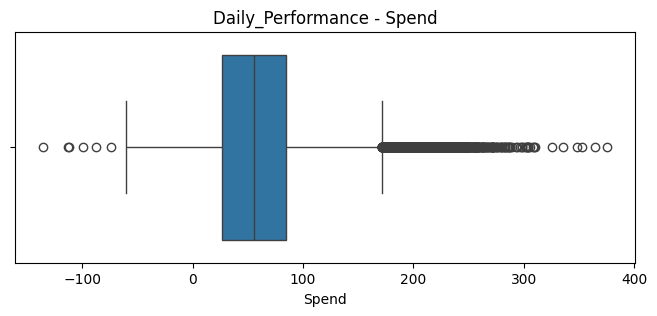

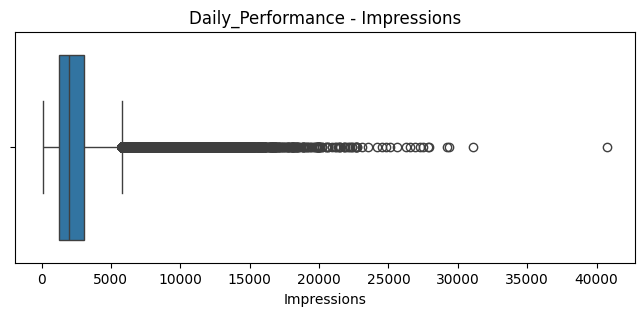

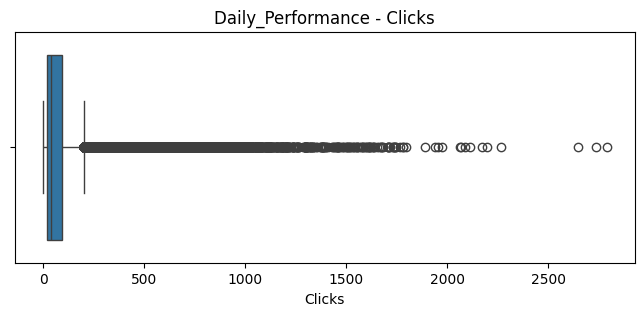

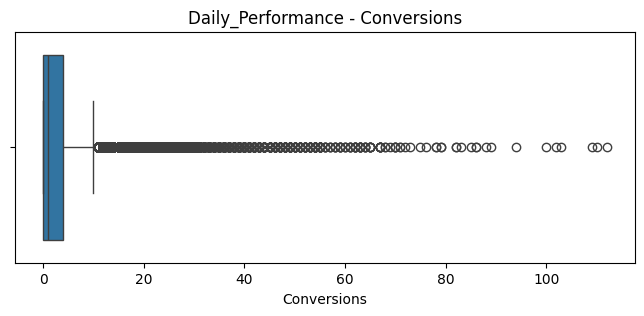

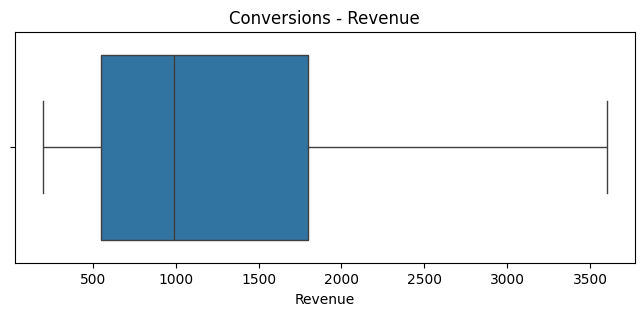

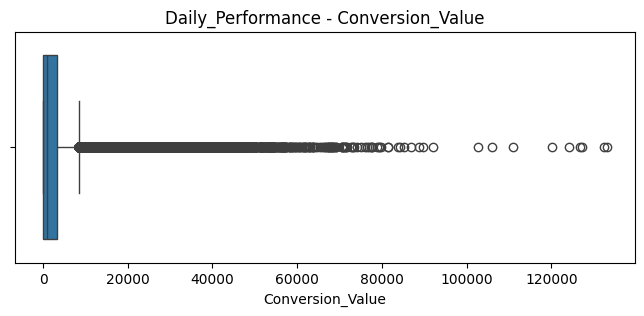

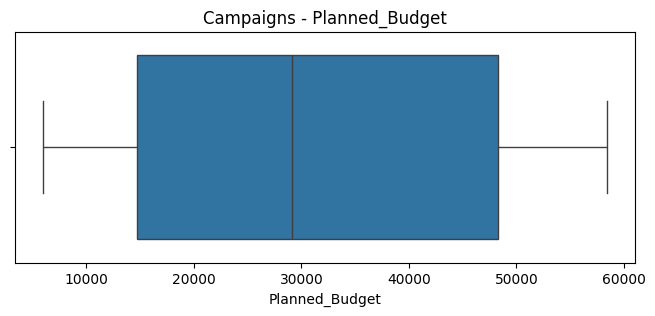

In [38]:
for col in columns:
    for name, df in dataframes.items():
        if col in df.columns:
            plt.figure(figsize=(8, 3))
            sns.boxplot(x=pd.to_numeric(df[col],
            errors="coerce").dropna())
            plt.title(f"{name} - {col}")
            plt.show()

In [40]:
for name, df in dataframes.items():
    for col in columns:
        if col in df.columns:
            values = pd.to_numeric(df[col], errors="coerce").dropna()

            q1 = values.quantile(.25)
            q3 = values.quantile(.75)
            iqr = q3 - q1

            count = ((values < q1 - 1.5 * iqr) |
                     (values > q3 + 1.5 * iqr)).sum()

            print(name, col, count)

Campaigns Planned_Budget 0
Daily_Performance Spend 3023
Daily_Performance Impressions 13236
Daily_Performance Clicks 23682
Daily_Performance Conversions 18806
Daily_Performance Conversion_Value 25085
Conversions Revenue 0


In [41]:
keys = {
    "Channels": "Channel_ID",
    "Campaigns": "Campaign_ID",
    "Ad_Groups": "AdGroup_ID",
    "Conversions": "Conversion_ID",
    "Touchpoints": "Touchpoint_ID"
}

for name, col in keys.items():
    print(name, dataframes[name][col].duplicated().sum())

Channels 0
Campaigns 0
Ad_Groups 0
Conversions 0
Touchpoints 40


In [42]:
relationships = [
    ("Campaigns", "Channel_ID", "Channels", "Channel_ID"),
    ("Ad_Groups", "Campaign_ID", "Campaigns", "Campaign_ID"),
    ("Daily_Performance", "Campaign_ID", "Campaigns", "Campaign_ID"),
    ("Daily_Performance", "AdGroup_ID", "Ad_Groups", "AdGroup_ID"),
    ("Daily_Performance", "Channel_ID", "Channels", "Channel_ID"),
    ("Conversions", "First_Touch_Channel_ID", "Channels", "Channel_ID"),
    ("Conversions", "Last_Touch_Channel_ID", "Channels", "Channel_ID"),
    ("Touchpoints", "Conversion_ID", "Conversions", "Conversion_ID"),
    ("Touchpoints", "Channel_ID", "Channels", "Channel_ID")
]

for child, col, parent, key in relationships:
    invalid = ~dataframes[child][col].isin(dataframes[parent][key])
    print(child, col, invalid.sum())

Campaigns Channel_ID 0
Ad_Groups Campaign_ID 0
Daily_Performance Campaign_ID 0
Daily_Performance AdGroup_ID 0
Daily_Performance Channel_ID 0
Conversions First_Touch_Channel_ID 0
Conversions Last_Touch_Channel_ID 0
Touchpoints Conversion_ID 0
Touchpoints Channel_ID 0


In [43]:
print("Missing Dates:")
for name, col in {
    "Campaigns": ["Start_Date", "End_Date"],
    "Daily_Performance": ["Date"],
    "Conversions": ["Conversion_Date"],
    "Touchpoints": ["Touch_Date"]
}.items():
    print(name)
    print(dataframes[name][col].isnull().sum())

Missing Dates:
Campaigns
Start_Date    8
End_Date      6
dtype: int64
Daily_Performance
Date    35
dtype: int64
Conversions
Conversion_Date    12
dtype: int64
Touchpoints
Touch_Date    20
dtype: int64


In [44]:
check_cols = ["Spend", "Impressions", "Clicks", "Conversions",
              "Revenue", "Conversion_Value", "Planned_Budget"]

for name, df in dataframes.items():
    for col in check_cols:
        if col in df.columns:
            values = pd.to_numeric(df[col], errors="coerce")
            print(name, col, (values < 0).sum())

Campaigns Planned_Budget 0
Daily_Performance Spend 15
Daily_Performance Impressions 0
Daily_Performance Clicks 0
Daily_Performance Conversions 0
Daily_Performance Conversion_Value 0
Conversions Revenue 0


In [45]:
df = dataframes["Daily_Performance"]

clicks = pd.to_numeric(df["Clicks"], errors="coerce")
impressions = pd.to_numeric(df["Impressions"], errors="coerce")

print("Clicks > Impressions:", (clicks > impressions).sum())

Clicks > Impressions: 0


In [46]:
raw_data = {name: df.copy() for name, df in dataframes.items()}
cleaned_data = {name: df.copy() for name, df in dataframes.items()}

In [47]:
for df in cleaned_data.values():
    cols = df.select_dtypes(include="object").columns
    df[cols] = df[cols].apply(lambda x: x.str.strip())

In [48]:
for df in cleaned_data.values():
    df.replace(r'^\s*$', np.nan, regex=True, inplace=True)

In [49]:
for name, df in cleaned_data.items():
    print(name, df.duplicated().sum())

Channels 0
Campaigns 0
Ad_Groups 0
Daily_Performance 120
Conversions 0
Touchpoints 40


In [50]:
for df in cleaned_data.values():
    df.drop_duplicates(inplace=True)

In [58]:
for col in ["Start_Date", "End_Date"]:
    cleaned_data["Campaigns"][col] = pd.to_datetime(cleaned_data["Campaigns"][col], errors="coerce")

In [59]:
for sheet, col in [("Daily_Performance", "Date"), ("Conversions", "Conversion_Date"), ("Touchpoints", "Touch_Date")]:
    cleaned_data[sheet][col] = pd.to_datetime(cleaned_data[sheet][col], errors="coerce")

In [54]:
for name, df in cleaned_data.items():
    print(name)
    print(df.isnull().sum())

Channels
Channel_ID       0
Channel_Name     0
Channel_Type     0
Platform         0
Channel_Group    0
Imported_By      0
Temp_Column      0
dtype: int64
Campaigns
Campaign_ID         0
Campaign_Name       0
Channel_ID          0
Objective           0
Target_Country      0
Target_Audience     0
Start_Date          8
End_Date            6
Planned_Budget      0
Campaign_Status     0
Internal_Comment    0
Legacy_Code         0
dtype: int64
Ad_Groups
AdGroup_ID          0
Campaign_ID         0
AdGroup_Name        0
Audience_Type       0
Device_Targeting    0
dtype: int64
Daily_Performance
Date                    35
Campaign_ID              0
AdGroup_ID               0
Channel_ID               0
Spend                  350
Impressions            180
Clicks              259700
Conversions            160
Conversion_Value       300
Upload_Batch             0
Unused_Flag              0
dtype: int64
Conversions
Conversion_ID                 0
Customer_ID                   0
Conversion_Date      

In [55]:
for name, df in cleaned_data.items():
    print(name)
    print((df.select_dtypes("number") < 0).sum())

Channels
Channel_ID     0
Temp_Column    0
dtype: int64
Campaigns
Campaign_ID       0
Channel_ID        0
Planned_Budget    0
dtype: int64
Ad_Groups
AdGroup_ID     0
Campaign_ID    0
dtype: int64
Daily_Performance
Campaign_ID          0
AdGroup_ID           0
Channel_ID           0
Spend               15
Impressions          0
Conversions          0
Conversion_Value     0
Upload_Batch         0
dtype: int64
Conversions
Conversion_ID             0
Customer_ID               0
First_Touch_Channel_ID    0
Last_Touch_Channel_ID     0
Touch_Count               0
dtype: int64
Touchpoints
Touchpoint_ID     0
Conversion_ID     0
Customer_ID       0
Channel_ID        0
Touch_Sequence    0
dtype: int64


In [56]:
for name, df in cleaned_data.items():
    print(name)
    print(df.dtypes)

Channels
Channel_ID        int64
Channel_Name     object
Channel_Type     object
Platform         object
Channel_Group    object
Imported_By      object
Temp_Column       int64
dtype: object
Campaigns
Campaign_ID           int64
Campaign_Name        object
Channel_ID            int64
Objective            object
Target_Country       object
Target_Audience      object
Start_Date           object
End_Date             object
Planned_Budget      float64
Campaign_Status      object
Internal_Comment     object
Legacy_Code          object
dtype: object
Ad_Groups
AdGroup_ID           int64
Campaign_ID          int64
AdGroup_Name        object
Audience_Type       object
Device_Targeting    object
dtype: object
Daily_Performance
Date                 object
Campaign_ID           int64
AdGroup_ID            int64
Channel_ID            int64
Spend               float64
Impressions         float64
Clicks               object
Conversions         float64
Conversion_Value    float64
Upload_Batch        

In [61]:
cols = ["Spend", "Impressions", "Clicks", "Conversions", "Conversion_Value"]

for col in cols:
    cleaned_data["Daily_Performance"][col] = pd.to_numeric(
        cleaned_data["Daily_Performance"][col].astype(str).str.replace(r"[^0-9.-]", "", regex=True),
        errors="coerce"
    )

In [62]:
cleaned_data["Conversions"]["Revenue"] = pd.to_numeric(
    cleaned_data["Conversions"]["Revenue"].astype(str).str.replace(r"[^0-9.-]", "", regex=True),
    errors="coerce"
)

In [63]:
cleaned_data["Campaigns"]["Planned_Budget"] = pd.to_numeric(
    cleaned_data["Campaigns"]["Planned_Budget"].astype(str).str.replace(r"[^0-9.-]", "", regex=True),
    errors="coerce"
)

In [64]:
for name, df in cleaned_data.items():
    print(name)
    print(df.dtypes)

Channels
Channel_ID        int64
Channel_Name     object
Channel_Type     object
Platform         object
Channel_Group    object
Imported_By      object
Temp_Column       int64
dtype: object
Campaigns
Campaign_ID                  int64
Campaign_Name               object
Channel_ID                   int64
Objective                   object
Target_Country              object
Target_Audience             object
Start_Date          datetime64[ns]
End_Date            datetime64[ns]
Planned_Budget             float64
Campaign_Status             object
Internal_Comment            object
Legacy_Code                 object
dtype: object
Ad_Groups
AdGroup_ID           int64
Campaign_ID          int64
AdGroup_Name        object
Audience_Type       object
Device_Targeting    object
dtype: object
Daily_Performance
Date                datetime64[ns]
Campaign_ID                  int64
AdGroup_ID                   int64
Channel_ID                   int64
Spend                      float64
Impressions  

In [65]:
for name, df in cleaned_data.items():
    print(name)
    print(df.isnull().sum())

Channels
Channel_ID       0
Channel_Name     0
Channel_Type     0
Platform         0
Channel_Group    0
Imported_By      0
Temp_Column      0
dtype: int64
Campaigns
Campaign_ID          0
Campaign_Name        0
Channel_ID           0
Objective            0
Target_Country       0
Target_Audience      0
Start_Date          82
End_Date            79
Planned_Budget       0
Campaign_Status      0
Internal_Comment     0
Legacy_Code          0
dtype: int64
Ad_Groups
AdGroup_ID          0
Campaign_ID         0
AdGroup_Name        0
Audience_Type       0
Device_Targeting    0
dtype: int64
Daily_Performance
Date                  1250
Campaign_ID              0
AdGroup_ID               0
Channel_ID               0
Spend                  350
Impressions            180
Clicks              259700
Conversions            160
Conversion_Value       300
Upload_Batch             0
Unused_Flag              0
dtype: int64
Conversions
Conversion_ID                 0
Customer_ID                   0
Conversio

In [66]:
for col in ["Start_Date", "End_Date"]:
    print(col, cleaned_data["Campaigns"][col].isnull().sum())

print("Daily:", cleaned_data["Daily_Performance"]["Date"].isnull().sum())
print("Conversions:", cleaned_data["Conversions"]["Conversion_Date"].isnull().sum())
print("Touchpoints:", cleaned_data["Touchpoints"]["Touch_Date"].isnull().sum())

Start_Date 82
End_Date 79
Daily: 1250
Conversions: 196
Touchpoints: 425


In [67]:
cols = ["Spend", "Impressions", "Clicks", "Conversions", "Conversion_Value"]

for col in cols:
    print(col, (cleaned_data["Daily_Performance"][col] < 0).sum())

Spend 15
Impressions 0
Clicks 0
Conversions 0
Conversion_Value 0


In [68]:
for name, df in cleaned_data.items():
    print(name, df.duplicated().sum())

Channels 0
Campaigns 0
Ad_Groups 0
Daily_Performance 0
Conversions 0
Touchpoints 0


In [69]:
print(cleaned_data["Channels"]["Channel_ID"].duplicated().sum())
print(cleaned_data["Campaigns"]["Campaign_ID"].duplicated().sum())
print(cleaned_data["Ad_Groups"]["AdGroup_ID"].duplicated().sum())
print(cleaned_data["Conversions"]["Conversion_ID"].duplicated().sum())
print(cleaned_data["Touchpoints"]["Touchpoint_ID"].duplicated().sum())

0
0
0
0
0


In [70]:
for name, df in cleaned_data.items():
    print(name, df.shape)

Channels (9, 7)
Campaigns (90, 12)
Ad_Groups (180, 5)
Daily_Performance (260000, 11)
Conversions (12000, 11)
Touchpoints (41936, 8)


In [71]:
for name in raw_data:
    print(name, "Before:", raw_data[name].shape[0],
          "After:", cleaned_data[name].shape[0])

Channels Before: 9 After: 9
Campaigns Before: 90 After: 90
Ad_Groups Before: 180 After: 180
Daily_Performance Before: 260120 After: 260000
Conversions Before: 12000 After: 12000
Touchpoints Before: 41976 After: 41936


In [74]:
print(spend.sort_values(ascending=False))

Channel_ID
YouTube Ads       2500824.18
TikTok Ads        2495483.95
Instagram Ads     2494081.59
Display Ads       2490528.95
FACEBOOK ADS      2484429.91
google ads        2480617.05
Direct              26364.83
Organic Search      26097.87
Email               26009.25
Name: Spend, dtype: float64


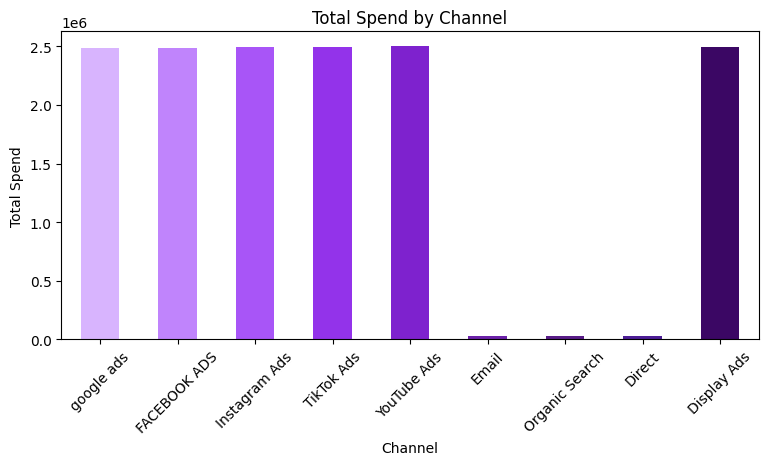

In [80]:
df = cleaned_data["Daily_Performance"]

spend = df.groupby("Channel_ID")["Spend"].sum()

spend.index = spend.index.map(
    cleaned_data["Channels"].set_index("Channel_ID")["Channel_Name"]
)

colors = ["#D8B4FE", "#C084FC", "#A855F7", "#9333EA",
          "#7E22CE", "#6B21A8", "#581C87", "#4C1D95", "#3B0764"]

spend.plot(kind="bar", figsize=(9, 4), color=colors[:len(spend)])

plt.title("Total Spend by Channel")
plt.xlabel("Channel")
plt.ylabel("Total Spend")
plt.xticks(rotation=45)
plt.show()

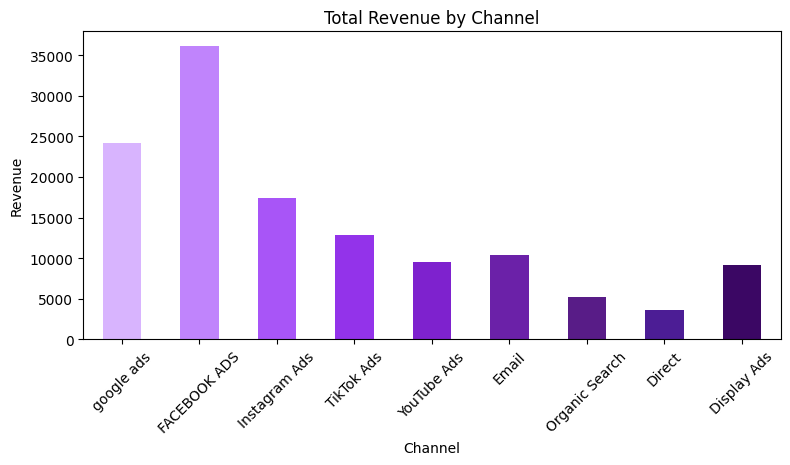

In [81]:
revenue = cleaned_data["Conversions"].groupby("Last_Touch_Channel_ID")["Revenue"].sum()

revenue.index = revenue.index.map(
    cleaned_data["Channels"].set_index("Channel_ID")["Channel_Name"]
)

colors = ["#D8B4FE", "#C084FC", "#A855F7", "#9333EA",
          "#7E22CE", "#6B21A8", "#581C87", "#4C1D95", "#3B0764"]

revenue.plot(kind="bar", figsize=(9, 4), color=colors[:len(revenue)])

plt.title("Total Revenue by Channel")
plt.xlabel("Channel")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.show()

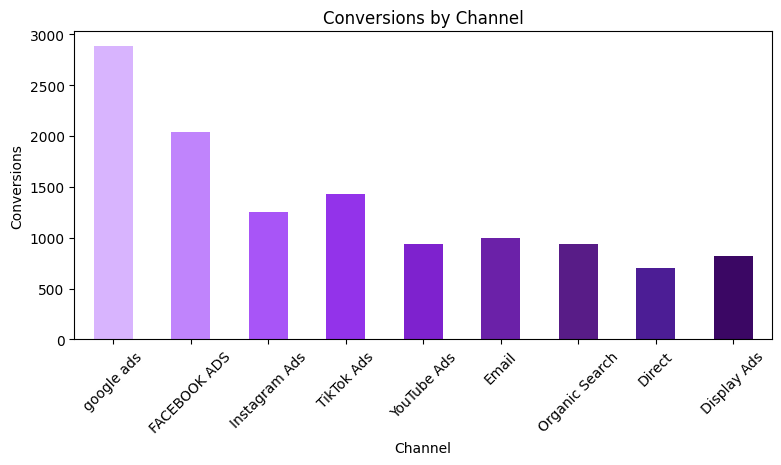

In [82]:
conversions = cleaned_data["Conversions"].groupby("Last_Touch_Channel_ID")["Conversion_ID"].count()

conversions.index = conversions.index.map(
    cleaned_data["Channels"].set_index("Channel_ID")["Channel_Name"]
)

colors = ["#D8B4FE", "#C084FC", "#A855F7", "#9333EA",
          "#7E22CE", "#6B21A8", "#581C87", "#4C1D95", "#3B0764"]

conversions.plot(
    kind="bar",
    figsize=(9, 4),
    color=colors[:len(conversions)]
)

plt.title("Conversions by Channel")
plt.xlabel("Channel")
plt.ylabel("Conversions")
plt.xticks(rotation=45)
plt.show()

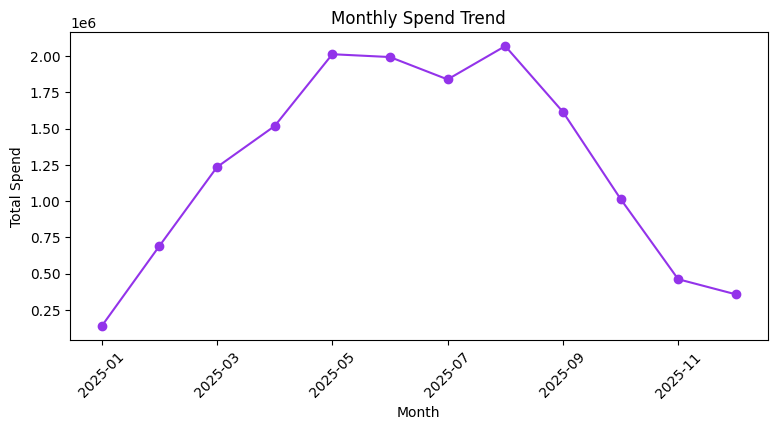

In [83]:
df = cleaned_data["Daily_Performance"].dropna(subset=["Date"])

monthly_spend = df.groupby(df["Date"].dt.to_period("M"))["Spend"].sum()

monthly_spend.index = monthly_spend.index.astype(str)

monthly_spend.plot(figsize=(9, 4), color="#9333EA", marker="o")

plt.title("Monthly Spend Trend")
plt.xlabel("Month")
plt.ylabel("Total Spend")
plt.xticks(rotation=45)
plt.show()